# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm

**Research question:** Can Genetic Algorithm (GA) based feature selection improve the classification performance of HOG features while reducing feature dimensionality on medical images?

**Plan:**
1. Load PneumoniaMNIST (128 × 128 chest X-rays, Normal vs Pneumonia) with its fixed train / validation / test split.
2. Extract HOG features with the parameters in Table 1 of the lab manual.
3. Baseline: HOG + SVM (RBF).
4. Proposed: GA selects a subset of HOG features (binary mask), then the same SVM is trained on the selected features.
5. Both models use the same split, scaler, classifier and tuning protocol. The test set is used only once, at the very end.

## 1. Setup

In [1]:
# medmnist is only needed to download the dataset (Colab already has its other dependencies)
import os
if not os.path.exists("data/pneumoniamnist_128.npz"):
    !pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.2 MB/s eta 0:00:00


In [2]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage.transform import resize
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)

IMG_SIZE = 128
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")
C_GRID = [1, 10, 100]          # SVM C values tried on the validation set (gamma = 'scale')

RERUN_GA = False               # False = reuse saved GA masks from results/ if they exist
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 2. Load the dataset

**Dataset:** PneumoniaMNIST from MedMNIST v2 / MedMNIST+ (Yang et al., 2023), derived from the pediatric chest X-ray dataset of Kermany et al. (2018). Licence: CC BY 4.0.
Labels: `0 = normal`, `1 = pneumonia`. We use the official split so that every run (and every model) sees exactly the same images.

The `.npz` file is downloaded once into `data/` (about 80 MB). If the download fails, download `pneumoniamnist_128.npz` from https://zenodo.org/records/10519652 and upload it to `data/` in the Colab file browser.

In [3]:
NPZ_PATH = "data/pneumoniamnist_128.npz"
if not os.path.exists(NPZ_PATH):
    from medmnist import PneumoniaMNIST
    PneumoniaMNIST(split="train", download=True, size=IMG_SIZE, root="data")

data = np.load(NPZ_PATH)
X_train_img, y_train = data["train_images"], data["train_labels"].ravel()
X_val_img,   y_val   = data["val_images"],   data["val_labels"].ravel()
X_test_img,  y_test  = data["test_images"],  data["test_labels"].ravel()
class_names = ["normal", "pneumonia"]

split_info = []
for name, X, y in [("train", X_train_img, y_train), ("val", X_val_img, y_val), ("test", X_test_img, y_test)]:
    counts = np.bincount(y, minlength=2)
    split_info.append([name, len(y), X.shape[1:], counts[0], counts[1], round(counts[1] / counts[0], 2)])
print(pd.DataFrame(split_info, columns=["split", "images", "shape", "normal", "pneumonia", "pneumonia/normal"]).to_string(index=False))

100%|██████████| 75.5M/75.5M [00:13<00:00, 5.59MB/s]


split  images      shape  normal  pneumonia  pneumonia/normal
train    4708 (128, 128)    1214       3494              2.88
  val     524 (128, 128)     135        389              2.88
 test     624 (128, 128)     234        390              1.67


The classes are imbalanced (roughly 3 pneumonia images for every normal one in train/val). Because of this we report macro-F1 and balanced accuracy, and the SVM uses `class_weight='balanced'`.

train: 0 images with NaN, 0 blank images
val: 0 images with NaN, 0 blank images
test: 0 images with NaN, 0 blank images


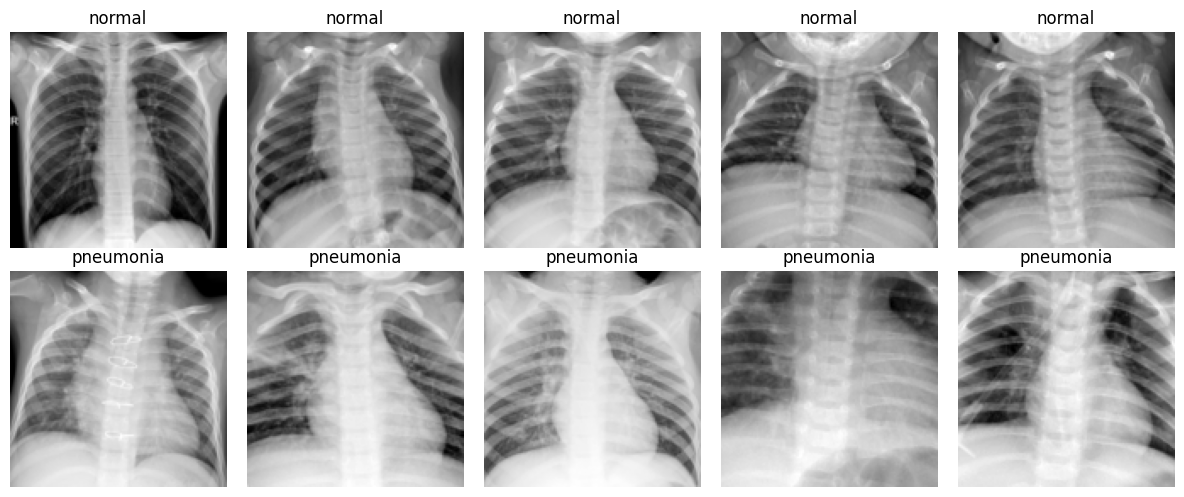

In [4]:
# Check for images that are broken (NaN) or blank (constant). These are reported, not silently dropped.
for name, X in [("train", X_train_img), ("val", X_val_img), ("test", X_test_img)]:
    flat = X.reshape(len(X), -1).astype(np.float32)
    n_nan = np.isnan(flat).any(axis=1).sum()
    n_blank = (flat.std(axis=1) == 0).sum()
    print(f"{name}: {n_nan} images with NaN, {n_blank} blank images")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for row, label in enumerate([0, 1]):
    idx = np.where(y_train == label)[0][:5]
    for col, i in enumerate(idx):
        axes[row, col].imshow(X_train_img[i], cmap="gray")
        axes[row, col].set_title(class_names[label])
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("figures/01_samples.png", dpi=120)
plt.show()

## 3. Preprocessing and HOG feature extraction

The images are already single-channel (grayscale). Each image is converted to grayscale if needed, resized to 128 × 128 (only if it is a different size) and scaled to [0, 1]. Then HOG is computed with the Table 1 parameters.

In [5]:
def preprocess(img):
    img = img.astype(np.float32) / 255.0
    if img.ndim == 3:                      # RGB -> grayscale
        img = img.mean(axis=2)
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = resize(img, (IMG_SIZE, IMG_SIZE), anti_aliasing=True)
    return img

def extract_hog(images):
    return np.array([hog(preprocess(img), **HOG_PARAMS) for img in images], dtype=np.float32)

t0 = time.time()
F_train = extract_hog(X_train_img)
F_val   = extract_hog(X_val_img)
F_test  = extract_hog(X_test_img)
hog_time = time.time() - t0

N_FEATURES = F_train.shape[1]
print("HOG feature length:", N_FEATURES)
print(f"HOG extraction time for all {len(F_train) + len(F_val) + len(F_test)} images: {hog_time:.1f} s")

HOG feature length: 8100
HOG extraction time for all 5856 images: 48.9 s


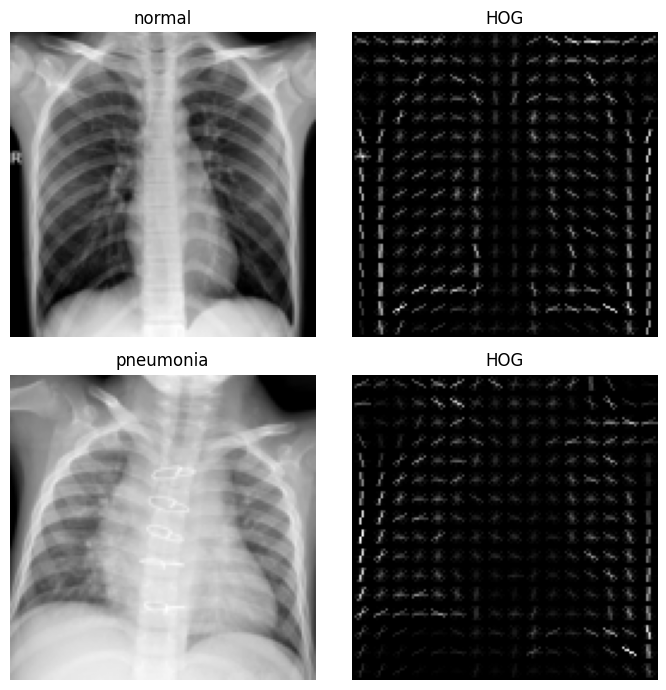

In [6]:
# HOG visualisation for one image of each class
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for row, label in enumerate([0, 1]):
    i = np.where(y_train == label)[0][0]
    _, hog_img = hog(preprocess(X_train_img[i]), visualize=True, **HOG_PARAMS)
    axes[row, 0].imshow(preprocess(X_train_img[i]), cmap="gray"); axes[row, 0].set_title(class_names[label])
    axes[row, 1].imshow(hog_img, cmap="gray"); axes[row, 1].set_title("HOG")
    axes[row, 0].axis("off"); axes[row, 1].axis("off")
plt.tight_layout()
plt.savefig("figures/02_hog_visualisation.png", dpi=120)
plt.show()

The scaler is fitted on the **training** set only and then applied to validation and test, so no information leaks from those sets. StandardScaler works feature by feature, so selecting columns later gives the same result as refitting it on the selected features.

In [7]:
scaler = StandardScaler().fit(F_train)
F_train_s = scaler.transform(F_train)
F_val_s   = scaler.transform(F_val)
F_test_s  = scaler.transform(F_test)

## 4. Evaluation function

Specificity is computed one-vs-rest for each class (TN / (TN + FP)) and then macro-averaged. For two classes this is the mean of the two classes' specificities.

In [8]:
def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    spec = []
    for c in range(len(cm)):
        tn = cm.sum() - cm[c, :].sum() - cm[:, c].sum() + cm[c, c]
        fp = cm[:, c].sum() - cm[c, c]
        spec.append(tn / (tn + fp))
    return {
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Precision (Macro, %)": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (Macro, %)": 100 * recall_score(y_true, y_pred, average="macro"),
        "Macro-F1 (%)": 100 * f1_score(y_true, y_pred, average="macro"),
        "Weighted-F1 (%)": 100 * f1_score(y_true, y_pred, average="weighted"),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y_true, y_pred),
        "Specificity (Macro, %)": 100 * np.mean(spec),
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred),
    }

def tune_and_train(Xtr, ytr, Xva, yva):
    # pick C with the best validation macro-F1, return the model trained on the training set
    best_f1, best_model, best_C, best_time = -1, None, None, None
    for C in C_GRID:
        t0 = time.time()
        model = SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced").fit(Xtr, ytr)
        fit_time = time.time() - t0
        f1 = f1_score(yva, model.predict(Xva), average="macro")
        print(f"  C={C:<4} validation macro-F1 = {f1:.4f}  (training time {fit_time:.1f} s)")
        if f1 > best_f1:
            best_f1, best_model, best_C, best_time = f1, model, C, fit_time
    return best_model, best_C, best_f1, best_time

## 5. Baseline: HOG + SVM

In [9]:
t0 = time.time()
base_model, base_C, base_val_f1, base_train_time = tune_and_train(F_train_s, y_train, F_val_s, y_val)
base_tune_time = time.time() - t0
print(f"Best C = {base_C}, validation macro-F1 = {base_val_f1:.4f}, training time of chosen model = {base_train_time:.1f} s")

  C=1    validation macro-F1 = 0.9553  (training time 50.3 s)
  C=10   validation macro-F1 = 0.9547  (training time 48.9 s)
  C=100  validation macro-F1 = 0.9547  (training time 48.3 s)
Best C = 1, validation macro-F1 = 0.9553, training time of chosen model = 50.3 s


## 6. Genetic Algorithm for HOG feature selection

- **Chromosome:** a binary mask of length 8100 (one gene per HOG feature). `1` = keep the feature, `0` = drop it.
- **Initial population:** each gene is set to 1 with probability 0.5.
- **Fitness:** `validation macro-F1 − λ × (selected features / 8100)` with λ = 0.05. Macro-F1 is used because the classes are imbalanced; the small penalty prefers smaller masks when two masks score about the same.
- **Speed-up:** training an RBF-SVM on all 4708 images for every chromosome is too slow for Colab, so during the GA each chromosome is scored by an SVM (C fixed to the baseline's best C) trained on a fixed, stratified subset of 600 training images and evaluated on the full validation set. The test set is never used here.
- **Selection:** tournament selection (size 3). **Crossover:** uniform crossover with probability 0.8. **Mutation:** bit-flip with probability `p_m` per gene. **Elitism:** the best 2 chromosomes are copied to the next generation.
- **Stopping:** maximum 12 generations, or stop early if the best fitness has not improved for 4 generations.

Two GA settings are compared: they differ only in mutation probability.

In [10]:
LAMBDA = 0.05
FIT_SUBSET = 600
N_GENERATIONS = 12
PATIENCE = 4
GA_SETTINGS = {
    "GA-A": dict(pop_size=12, mut_prob=0.01),
    "GA-B": dict(pop_size=12, mut_prob=0.05),
}

# fixed training subset used only inside the fitness function
sub_idx, _ = train_test_split(np.arange(len(y_train)), train_size=FIT_SUBSET, stratify=y_train, random_state=SEED)
F_sub, y_sub = F_train_s[sub_idx], y_train[sub_idx]

def fitness(mask):
    if mask.sum() == 0:
        return 0.0, 0.0
    model = SVC(kernel="rbf", C=base_C, gamma="scale", class_weight="balanced")
    model.fit(F_sub[:, mask], y_sub)
    f1 = f1_score(y_val, model.predict(F_val_s[:, mask]), average="macro")
    return f1 - LAMBDA * mask.mean(), f1

def tournament(pop, scores, rng, k=3):
    idx = rng.choice(len(pop), k, replace=False)
    return pop[idx[np.argmax(scores[idx])]]

def crossover(p1, p2, rng, prob=0.8):
    if rng.random() > prob:
        return p1.copy()
    take_from_p1 = rng.random(len(p1)) < 0.5
    return np.where(take_from_p1, p1, p2)

def mutate(child, rng, mut_prob):
    flip = rng.random(len(child)) < mut_prob
    return np.logical_xor(child, flip)

def run_ga(pop_size, mut_prob, n_elite=2):
    rng = np.random.default_rng(SEED)
    pop = rng.random((pop_size, N_FEATURES)) < 0.5
    history, best_mask, best_fit, no_improve = [], None, -1, 0
    for gen in range(N_GENERATIONS):
        results = [fitness(m) for m in pop]
        scores = np.array([r[0] for r in results])
        f1s = np.array([r[1] for r in results])
        b = np.argmax(scores)
        if scores[b] > best_fit + 1e-6:
            best_fit, best_mask, no_improve = scores[b], pop[b].copy(), 0
        else:
            no_improve += 1
        history.append({"generation": gen + 1, "best_fitness": scores.max(), "mean_fitness": scores.mean(),
                        "best_val_f1": f1s[b], "best_n_features": int(pop[b].sum())})
        print(f"  gen {gen+1:2d}: best fitness {scores.max():.4f} | mean {scores.mean():.4f} | "
              f"val F1 {f1s[b]:.4f} | features {pop[b].sum()}")
        if no_improve >= PATIENCE:
            print("  early stop: no improvement for", PATIENCE, "generations")
            break
        # next generation: elites + children
        elite = pop[np.argsort(scores)[::-1][:n_elite]]
        children = [mutate(crossover(tournament(pop, scores, rng), tournament(pop, scores, rng), rng), rng, mut_prob)
                    for _ in range(pop_size - n_elite)]
        pop = np.vstack([elite, children])
    return best_mask, best_fit, pd.DataFrame(history)

In [11]:
ga_results = {}
for name, cfg in GA_SETTINGS.items():
    mask_file, hist_file = f"results/{name}_best_mask.npy", f"results/{name}_history.csv"
    if not RERUN_GA and os.path.exists(mask_file) and os.path.exists(f"results/{name}_meta.json"):
        print(f"{name}: loading saved mask from {mask_file}")
        mask, hist = np.load(mask_file), pd.read_csv(hist_file)
        meta = json.load(open(f"results/{name}_meta.json"))
        ga_time, best_fit = meta["ga_time_s"], meta["best_fitness"]
    else:
        print(f"{name}: running GA {cfg}")
        t0 = time.time()
        mask, best_fit, hist = run_ga(**cfg)
        ga_time = time.time() - t0
        np.save(mask_file, mask)
        hist.to_csv(hist_file, index=False)
        json.dump({"ga_time_s": ga_time, "best_fitness": float(best_fit), **cfg}, open(f"results/{name}_meta.json", "w"))
    ga_results[name] = dict(mask=mask, history=hist, ga_time=ga_time, best_fitness=best_fit, **cfg)
    print(f"{name}: best fitness {best_fit:.4f}, {mask.sum()} / {N_FEATURES} features kept, GA time {ga_time/60:.1f} min\n")

GA-A: running GA {'pop_size': 12, 'mut_prob': 0.01}
  gen  1: best fitness 0.9173 | mean 0.9133 | val F1 0.9419 | features 3992
  gen  2: best fitness 0.9195 | mean 0.9153 | val F1 0.9443 | features 4017
  gen  3: best fitness 0.9195 | mean 0.9166 | val F1 0.9443 | features 4012
  gen  4: best fitness 0.9195 | mean 0.9170 | val F1 0.9443 | features 4012
  gen  5: best fitness 0.9196 | mean 0.9175 | val F1 0.9443 | features 4009
  gen  6: best fitness 0.9220 | mean 0.9183 | val F1 0.9467 | features 4004
  gen  7: best fitness 0.9248 | mean 0.9178 | val F1 0.9494 | features 3987
  gen  8: best fitness 0.9248 | mean 0.9206 | val F1 0.9494 | features 3980
  gen  9: best fitness 0.9249 | mean 0.9226 | val F1 0.9494 | features 3965
  gen 10: best fitness 0.9249 | mean 0.9220 | val F1 0.9494 | features 3965
  gen 11: best fitness 0.9251 | mean 0.9229 | val F1 0.9494 | features 3936
  gen 12: best fitness 0.9251 | mean 0.9238 | val F1 0.9494 | features 3936
GA-A: best fitness 0.9251, 3936 / 81

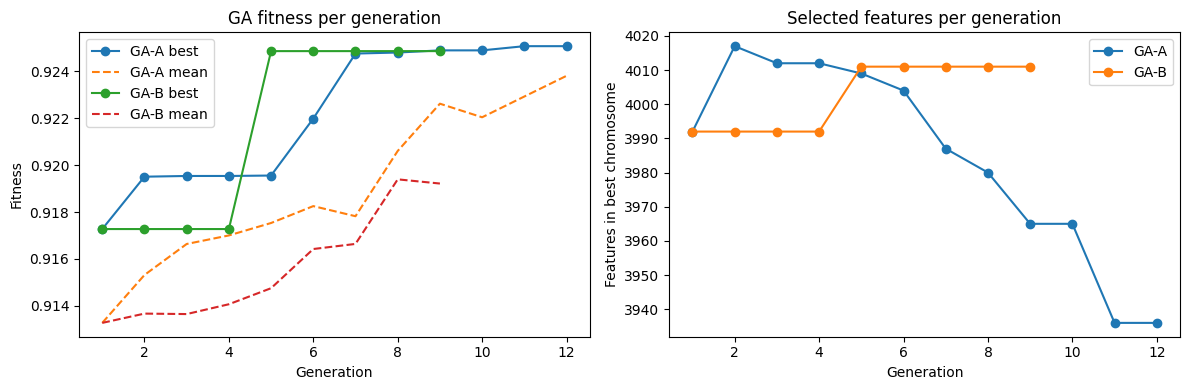

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in ga_results.items():
    h = r["history"]
    axes[0].plot(h["generation"], h["best_fitness"], marker="o", label=f"{name} best")
    axes[0].plot(h["generation"], h["mean_fitness"], linestyle="--", label=f"{name} mean")
    axes[1].plot(h["generation"], h["best_n_features"], marker="o", label=name)
axes[0].set_xlabel("Generation"); axes[0].set_ylabel("Fitness"); axes[0].set_title("GA fitness per generation"); axes[0].legend()
axes[1].set_xlabel("Generation"); axes[1].set_ylabel("Features in best chromosome"); axes[1].set_title("Selected features per generation"); axes[1].legend()
plt.tight_layout()
plt.savefig("figures/03_ga_fitness.png", dpi=120)
plt.show()

## 7. GA-HOG + SVM

For each GA setting, the selected features are used to train the same SVM with the same protocol as the baseline (C tuned on the validation set, final model trained on the full training set).
The setting used as **the** proposed model is chosen by **validation** macro-F1, not by test results.

In [12]:
for name, r in ga_results.items():
    print(name)
    mask = r["mask"]
    t0 = time.time()
    r["model"], r["C"], r["val_f1"], r["train_time"] = tune_and_train(F_train_s[:, mask], y_train, F_val_s[:, mask], y_val)
    r["tune_time"] = time.time() - t0

setting_table = pd.DataFrame([{
    "Setting": n, "Population": r["pop_size"], "Mutation prob.": r["mut_prob"],
    "Generations run": len(r["history"]), "Best GA fitness": round(r["best_fitness"], 4),
    "Features kept": int(r["mask"].sum()), "Kept (%)": round(100 * r["mask"].mean(), 1),
    "Val macro-F1 (full train)": round(r["val_f1"], 4), "GA time (min)": round(r["ga_time"] / 60, 1)}
    for n, r in ga_results.items()])
print(setting_table.to_string(index=False))
print(f"\nBaseline validation macro-F1: {base_val_f1:.4f}")

# highest validation macro-F1; if tied, the one with fewer features
best_setting = max(ga_results, key=lambda n: (ga_results[n]["val_f1"], -ga_results[n]["mask"].sum()))
print("Chosen GA setting (by validation macro-F1):", best_setting)

GA-A
  C=1    validation macro-F1 = 0.9605  (training time 24.0 s)
  C=10   validation macro-F1 = 0.9549  (training time 23.7 s)
  C=100  validation macro-F1 = 0.9549  (training time 23.6 s)
GA-B
  C=1    validation macro-F1 = 0.9501  (training time 24.2 s)
  C=10   validation macro-F1 = 0.9520  (training time 24.1 s)
  C=100  validation macro-F1 = 0.9520  (training time 24.1 s)
Setting  Population  Mutation prob.  Generations run  Best GA fitness  Features kept  Kept (%)  Val macro-F1 (full train)  GA time (min)
   GA-A          12            0.01               12           0.9251           3936      48.6                     0.9605            3.8
   GA-B          12            0.05                9           0.9249           4011      49.5                     0.9520            2.9

Baseline validation macro-F1: 0.9553
Chosen GA setting (by validation macro-F1): GA-A


## 8. Final evaluation on the test set

Model selection is finished at this point. The test set is used here for the first time.

In [13]:
best = ga_results[best_setting]
mask = best["mask"]

t0 = time.time(); base_pred = base_model.predict(F_test_s); base_inf_time = time.time() - t0
t0 = time.time(); ga_pred = best["model"].predict(F_test_s[:, mask]); ga_inf_time = time.time() - t0

base_metrics = evaluate(y_test, base_pred)
ga_metrics = evaluate(y_test, ga_pred)

table2 = pd.DataFrame({"HOG + SVM (Baseline)": base_metrics, f"GA-HOG + SVM ({best_setting})": ga_metrics})
table2["Improvement"] = table2.iloc[:, 1] - table2.iloc[:, 0]
print("Table 2. Test-set comparison")
print(table2.round(2).to_string())

Table 2. Test-set comparison
                                  HOG + SVM (Baseline)  GA-HOG + SVM (GA-A)  Improvement
Accuracy (%)                                     86.54                86.22        -0.32
Precision (Macro, %)                             90.15                89.73        -0.42
Recall (Macro, %)                                82.39                82.05        -0.34
Macro-F1 (%)                                     84.38                84.01        -0.37
Weighted-F1 (%)                                  85.83                85.49        -0.34
Balanced accuracy (%)                            82.39                82.05        -0.34
Specificity (Macro, %)                           82.39                82.05        -0.34
Cohen's kappa                                     0.69                 0.69        -0.01
Matthews correlation coefficient                  0.72                 0.71        -0.01


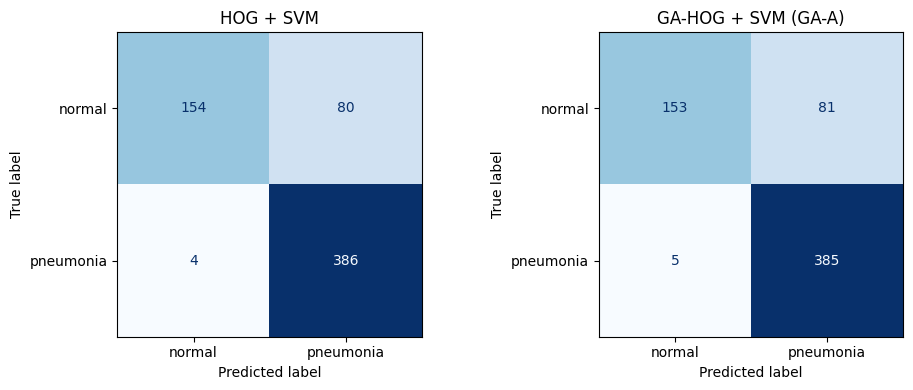

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], base_pred, "HOG + SVM"), (axes[1], ga_pred, f"GA-HOG + SVM ({best_setting})")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/04_confusion_matrices.png", dpi=120)
plt.show()

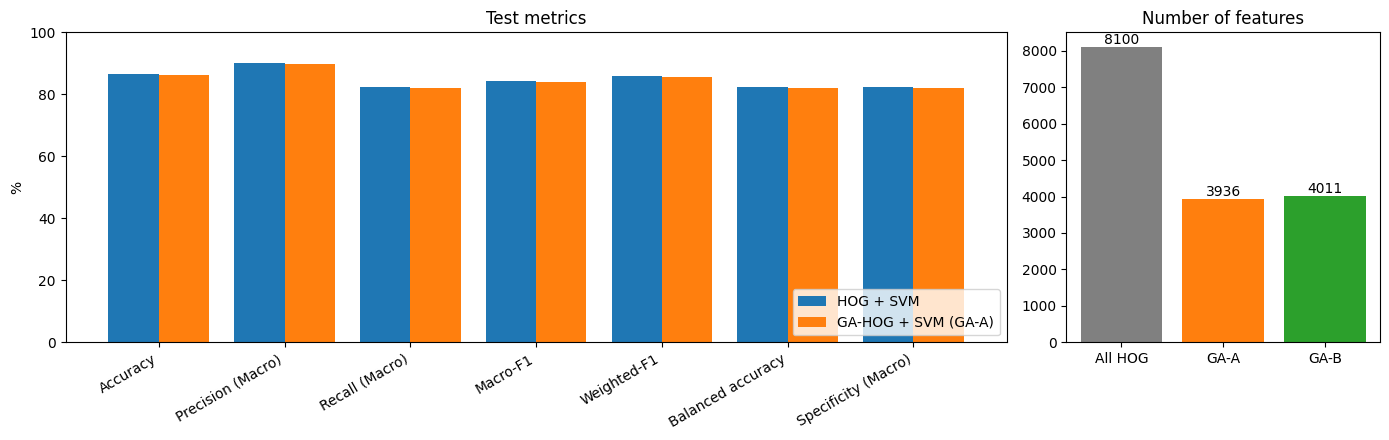

In [15]:
pct_metrics = [m for m in base_metrics if "%" in m]
x = np.arange(len(pct_metrics))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [3, 1]})
axes[0].bar(x - 0.2, [base_metrics[m] for m in pct_metrics], 0.4, label="HOG + SVM")
axes[0].bar(x + 0.2, [ga_metrics[m] for m in pct_metrics], 0.4, label=f"GA-HOG + SVM ({best_setting})")
axes[0].set_xticks(x); axes[0].set_xticklabels([m.replace(" (%)", "").replace(", %", "") for m in pct_metrics], rotation=30, ha="right")
axes[0].set_ylabel("%"); axes[0].set_ylim(0, 100); axes[0].set_title("Test metrics"); axes[0].legend(loc="lower right")

counts = [N_FEATURES] + [int(r["mask"].sum()) for r in ga_results.values()]
axes[1].bar(["All HOG"] + list(ga_results), counts, color=["gray", "tab:orange", "tab:green"])
for i, c in enumerate(counts):
    axes[1].text(i, c, str(c), ha="center", va="bottom")
axes[1].set_title("Number of features")
plt.tight_layout()
plt.savefig("figures/05_metrics_and_features.png", dpi=120)
plt.show()

In [16]:
cost = pd.DataFrame({
    "HOG + SVM": {"Features": N_FEATURES, "Features kept (%)": 100.0, "GA search time (s)": 0.0,
                  "C tuning time (s)": base_tune_time, "Training time, chosen C (s)": base_train_time,
                  "Test inference time (s)": base_inf_time},
    f"GA-HOG + SVM ({best_setting})": {"Features": int(mask.sum()), "Features kept (%)": 100 * mask.mean(),
                  "GA search time (s)": best["ga_time"], "C tuning time (s)": best["tune_time"],
                  "Training time, chosen C (s)": best["train_time"], "Test inference time (s)": ga_inf_time},
})
print(f"HOG extraction time (shared by both models): {hog_time:.1f} s\n")
print(cost.round(2).to_string())

HOG extraction time (shared by both models): 48.9 s

                             HOG + SVM  GA-HOG + SVM (GA-A)
Features                       8100.00              3936.00
Features kept (%)               100.00                48.59
GA search time (s)                0.00               225.99
C tuning time (s)               172.17                83.10
Training time, chosen C (s)      50.26                24.04
Test inference time (s)           9.85                 4.50


**Supplementary:** test results of the GA setting that was *not* chosen. This is shown only for completeness; it was not used for any decision.

In [17]:
for name, r in ga_results.items():
    if name != best_setting:
        other = evaluate(y_test, r["model"].predict(F_test_s[:, r["mask"]]))
        print(pd.DataFrame({name: other}).round(2).to_string())

                                   GA-B
Accuracy (%)                      84.13
Precision (Macro, %)              89.57
Recall (Macro, %)                 78.93
Macro-F1 (%)                      81.01
Weighted-F1 (%)                   82.94
Balanced accuracy (%)             78.93
Specificity (Macro, %)            78.93
Cohen's kappa                      0.63
Matthews correlation coefficient   0.68


## 9. Save results

In [18]:
table1 = pd.DataFrame({
    "Parameter": ["Medical dataset", "Image resolution", "HOG orientations", "Pixels per cell", "Cells per block",
                  "Block normalization", "Feature selection", "Classifier", "SVM kernel", "Hyperparameter tuning",
                  "Data split", "Random seed"],
    "Baseline: HOG + SVM": ["PneumoniaMNIST", "128 × 128", 9, "8×8", "2×2", "L2-Hys", "None", "SVM", "RBF",
                            f"Validation set (C={base_C})", "Official MedMNIST split", SEED],
    "Proposed: GA-HOG + SVM": ["PneumoniaMNIST", "128 × 128", 9, "8×8", "2×2", "L2-Hys", f"Genetic Algorithm ({best_setting})",
                               "SVM", "RBF", f"Validation set (C={best['C']})", "Official MedMNIST split", SEED],
})
table1.to_csv("results/table1_configuration.csv", index=False)
table2.round(4).to_csv("results/table2_test_comparison.csv")
setting_table.to_csv("results/ga_settings_comparison.csv", index=False)
cost.round(3).to_csv("results/computational_cost.csv")

summary = pd.DataFrame([
    {"model": "HOG + SVM", "n_features": N_FEATURES, "pct_features": 100.0, **base_metrics},
    {"model": f"GA-HOG + SVM ({best_setting})", "n_features": int(mask.sum()), "pct_features": 100 * mask.mean(), **ga_metrics},
])
summary.round(4).to_csv("results/results_summary.csv", index=False)
print(table1.to_string(index=False))
print("\nSaved:", sorted(os.listdir("results")))

            Parameter     Baseline: HOG + SVM   Proposed: GA-HOG + SVM
      Medical dataset          PneumoniaMNIST           PneumoniaMNIST
     Image resolution               128 × 128                128 × 128
     HOG orientations                       9                        9
      Pixels per cell                     8×8                      8×8
      Cells per block                     2×2                      2×2
  Block normalization                  L2-Hys                   L2-Hys
    Feature selection                    None Genetic Algorithm (GA-A)
           Classifier                     SVM                      SVM
           SVM kernel                     RBF                      RBF
Hyperparameter tuning    Validation set (C=1)     Validation set (C=1)
           Data split Official MedMNIST split  Official MedMNIST split
          Random seed                      42                       42

Saved: ['GA-A_best_mask.npy', 'GA-A_history.csv', 'GA-A_meta.json', 'GA-B_be

## 10. Final verification and summary

In [19]:
assert len(F_train) == len(y_train) and len(F_val) == len(y_val) and len(F_test) == len(y_test)
assert N_FEATURES == 8100, "HOG length should be 15 x 15 blocks x 2 x 2 cells x 9 bins = 8100"
assert mask.dtype == bool and mask.shape == (N_FEATURES,)

d_f1 = ga_metrics["Macro-F1 (%)"] - base_metrics["Macro-F1 (%)"]
d_bacc = ga_metrics["Balanced accuracy (%)"] - base_metrics["Balanced accuracy (%)"]
print(f"Dataset: PneumoniaMNIST 128x128 | train {len(y_train)}, val {len(y_val)}, test {len(y_test)}")
print(f"HOG features: {N_FEATURES} -> GA kept {mask.sum()} ({100*mask.mean():.1f}%) using {best_setting}")
print(f"Test macro-F1:          baseline {base_metrics['Macro-F1 (%)']:.2f}%  vs  GA {ga_metrics['Macro-F1 (%)']:.2f}%  ({d_f1:+.2f} points)")
print(f"Test balanced accuracy: baseline {base_metrics['Balanced accuracy (%)']:.2f}%  vs  GA {ga_metrics['Balanced accuracy (%)']:.2f}%  ({d_bacc:+.2f} points)")
print(f"Extra cost of GA search: {best['ga_time']/60:.1f} min")
if d_f1 > 0:
    print("Result: GA feature selection gave a higher test macro-F1 with fewer features.")
elif d_f1 == 0:
    print("Result: same test macro-F1 with fewer features.")
else:
    print("Result: GA feature selection reduced the number of features but did NOT improve test macro-F1.")
print("Note: one fixed split and one seed, so differences of about 1 point may be noise.")

Dataset: PneumoniaMNIST 128x128 | train 4708, val 524, test 624
HOG features: 8100 -> GA kept 3936 (48.6%) using GA-A
Test macro-F1:          baseline 84.38%  vs  GA 84.01%  (-0.37 points)
Test balanced accuracy: baseline 82.39%  vs  GA 82.05%  (-0.34 points)
Extra cost of GA search: 3.8 min
Result: GA feature selection reduced the number of features but did NOT improve test macro-F1.
Note: one fixed split and one seed, so differences of about 1 point may be noise.


## 11. Discussion

*(Write the final interpretation using the numbers printed above.)*

**Strengths.** The GA searches over feature subsets directly using the classifier's own validation score, so it can drop HOG features that carry little information (for example cells in the black border around the X-ray) without needing any extra model. The selected mask is easy to inspect and to reuse, and a smaller feature vector makes the final SVM cheaper to train and use.

**Limitations.**
- The GA fitness and the choice of the best chromosome both use the same validation set, so the validation score of the GA model is optimistic. The test set gives the fair comparison.
- To keep Colab runtime reasonable, fitness is computed with an SVM trained on 600 training images, so the selected mask may not be the best one for the full training set.
- Small population (12) and few generations (12) relative to 8100 genes: the GA only explores a small part of the search space, and the starting masks keep about half of the features.
- Results come from one fixed split and one seed; no confidence intervals.
- MedMNIST does not provide patient IDs, so patient-level separation between splits cannot be checked here (we rely on the official split).

**Computational cost.** HOG extraction is shared by both models. The GA adds one SVM fit + prediction per chromosome per generation (up to 12 × 12 = 144 fits per setting), which is by far the most expensive step; this cost is paid once, during training, and not at prediction time.

In [21]:
!zip -r lab07_results.zip results figures
from google.colab import files
files.download("lab07_results.zip")

  adding: results/ (stored 0%)
  adding: results/GA-B_meta.json (deflated 10%)
  adding: results/GA-B_best_mask.npy (deflated 82%)
  adding: results/GA-A_history.csv (deflated 60%)
  adding: results/computational_cost.csv (deflated 28%)
  adding: results/table1_configuration.csv (deflated 37%)
  adding: results/GA-A_best_mask.npy (deflated 82%)
  adding: results/GA-B_history.csv (deflated 68%)
  adding: results/ga_settings_comparison.csv (deflated 21%)
  adding: results/results_summary.csv (deflated 36%)
  adding: results/table2_test_comparison.csv (deflated 39%)
  adding: results/GA-A_meta.json (deflated 12%)
  adding: figures/ (stored 0%)
  adding: figures/02_hog_visualisation.png (deflated 2%)
  adding: figures/03_ga_fitness.png (deflated 7%)
  adding: figures/01_samples.png (deflated 1%)
  adding: figures/04_confusion_matrices.png (deflated 20%)
  adding: figures/05_metrics_and_features.png (deflated 16%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>